# IFAC fixed-uncertain-pole benchmark — final scientific consolidation (CPU)

**Reproducible executable package.** Run all. Only the **quick** profile runs automatically in this notebook to keep Colab CPU time modest; the release ZIP includes the saved **standard** profile and comprehensive manuscript. Claims of novelty and submission eligibility remain unresolved; this is not an endorsement of journal publication.

Scientific distinction: exact-rational full-interval stability certificates vs exact per-plant limiting second moments vs finite-grid maxima vs finite-horizon Monte Carlo. Gain values are interpreted as exact dyadic reals for certification.

In [1]:
import sys,platform,os,io,base64,zipfile,pathlib,importlib
from IPython.display import display, Markdown, Image
from pathlib import Path
import numpy,scipy,sympy,matplotlib,pandas,pytest
print('Python',sys.version.split()[0],'NumPy',numpy.__version__,'SciPy',scipy.__version__,'SymPy',sympy.__version__)
BASE=Path.cwd()/'ifac_cpu_workspace'
BASE.mkdir(parents=True,exist_ok=True)


Python 3.13.5 NumPy 2.3.5 SciPy 1.17.0 SymPy 1.14.0


In [2]:
import base64, io, zipfile
payload = '...'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as archive:
    archive.extractall(BASE)
print('Extracted verified research scripts to:',BASE)
print('Files:',len(list(BASE.rglob('*.py'))))

Extracted verified research scripts to: /mnt/data/IFAC_2026_submission_consolidation/notebook/ifac_cpu_workspace
Files: 14


In [3]:
import subprocess
p=subprocess.run([sys.executable,'-m','pytest','-q','tests/'],cwd=BASE,capture_output=True,text=True,env={**os.environ,'PYTHONPATH':str(BASE/'src')+os.pathsep+str(BASE/'code')})
print(p.stdout,p.stderr)
assert p.returncode==0, 'Regression tests failed'


....................                                                     [100%]
20 passed in 1.23s
 


In [4]:
# Run all primary v3 baselines: oracle, stationary, nominal deadbeat,
# ordinary Chebyshev, optimized periodic, two-sample, and open loop.
# The quick profile does NOT replace standard-profile evidence included in ZIP.
p=subprocess.run([sys.executable,'run_benchmark.py','--profile','quick'],cwd=BASE,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
print(p.stdout[-6000:]);assert p.returncode==0, 'Main benchmark failed'


COMPLETE 1.95 sec (63, 21) tests rerun separately with pytest
 a1  a2    q  lp_grid_peak  continuum_bound_float  continuum_contraction
1.2 3.0 0.92      0.069089               0.075665                   True
1.2 3.0 0.96      0.028693               0.028997                   True
1.5 4.5 0.98      0.687903               0.697340                   True
 a1  a2   a    q   controller                    per_plant_status   exact_J     mean_J_MC
1.2 3.0 1.2 0.92       oracle            exact_fixed_plant_stable  0.012051  2.504316e-02
1.2 3.0 1.2 0.92   stationary          exact_fixed_plant_unstable       inf  3.422415e+00
1.2 3.0 1.2 0.92      nominal            exact_fixed_plant_stable  0.086165  1.727210e-01
1.2 3.0 1.2 0.92         cheb            exact_fixed_plant_stable  0.096951  4.872699e-01
1.2 3.0 1.2 0.92    optimized            exact_fixed_plant_stable  0.163667  1.766789e-01
1.2 3.0 1.2 0.92 two_received   exact_spectral_fixed_plant_stable       NaN  6.782804e-02
1.2 3.0 1.2 0.92

In [5]:
# Run independent cost-aware stationary optimized baseline, deterministic
# exact moment curves, 64-piece exact Bernstein continuum certificate,
# and paired finite-horizon Monte Carlo with separate RNG seed.
p=subprocess.run([sys.executable,'code/run_consolidation.py','--profile','quick'],cwd=BASE,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
print(p.stdout[-6000:]);assert p.returncode==0, 'Cost-aware experiment failed'


Certified stable: True Worst J costaware 0.28034528089355604 original 0.33940195652173855
Simulation rows: [{'a': 1.2, 'q': 0.96, 'controller': 'threshold_optimal', 'N': 500, 'T': 250, 'finite_horizon_mean_J': 0.24460552500099633, 'finite_horizon_median_J': 0.15214740252036857, 'finite_horizon_peak_x_mean': 1.6056603918238366, 'finite_horizon_peak_u_mean': 3.371886822830057, 'asymptotic_exact_J': 0.2304936886395526, 'exact_asymptotic_Ex2': 0.1899867129253721, 'exact_asymptotic_Eu2': 0.8101395142836101, 'interpretation': 'finite horizon MC mean is NOT estimator of steady-state in early/transient observation windows'}, {'a': 1.2, 'q': 0.96, 'controller': 'cost_aware_locally_optimized', 'N': 500, 'T': 250, 'finite_horizon_mean_J': 0.28297752520696057, 'finite_horizon_median_J': 0.1669802913878599, 'finite_horizon_peak_x_mean': 1.6805934139272343, 'finite_horizon_peak_u_mean': 3.5371318540388765, 'asymptotic_exact_J': 0.28034528089342986, 'exact_asymptotic_Ex2': 0.23089401776849602, 'exact

In [6]:
import json,pandas as pd
r=BASE/'results'
cost=json.loads((r/'cost_aware_stationary.json').read_text())
cert=json.loads((r/'weighted_periodic_exact_certificates.json').read_text())
assert cost['certificate']['certified'] and len(cert)==3
assert all(v['bound_less_than_one_exact'] for v in cert)
print('Cost-aware exact Bernstein continuum stability:',cost['certificate']['certified'])
print('Optimized L, B:',cost['L'],cost['B'])
print('1001-point grid max exact J baseline',cost['benchmark_J_hstar'],'cost-aware',cost['max_dense_grid_J'])
print('All period-six continuum exact rational certificates: PASS')
display(pd.read_csv(r/'thresholds.csv'))
display(pd.read_csv(r/'cost_aware_paired_simulation.csv')[['a','controller','finite_horizon_mean_J','asymptotic_exact_J']])


Cost-aware exact Bernstein continuum stability: True
Optimized L, B: 2.104692202603161 0.8143494389928447
1001-point grid max exact J baseline 0.33940195652173855 cost-aware 0.28034528089355604
All period-six continuum exact rational certificates: PASS


,a1,a2,q,q_known_a2,q_stationary,q_cheb_m6,q_cheb_m32,stationary_robust,cheb_m6_robust
0,1.2,3.0,0.92,0.888889,0.947222,0.914822,0.910277,False,True
1,1.2,3.0,0.96,0.888889,0.947222,0.914822,0.910277,True,True
2,1.5,4.5,0.98,0.950617,1.185185,0.985093,0.979016,False,False


,a,controller,finite_horizon_mean_J,asymptotic_exact_J
0,1.2,threshold_optimal,0.244606,0.230494
1,1.2,cost_aware_locally_optimized,0.282978,0.280345
2,2.1,threshold_optimal,0.021330,0.015556
3,2.1,cost_aware_locally_optimized,0.021372,0.015593
4,3.0,threshold_optimal,0.406221,0.339402
5,3.0,cost_aware_locally_optimized,0.348379,0.280345


fig01_periodic_stability.png


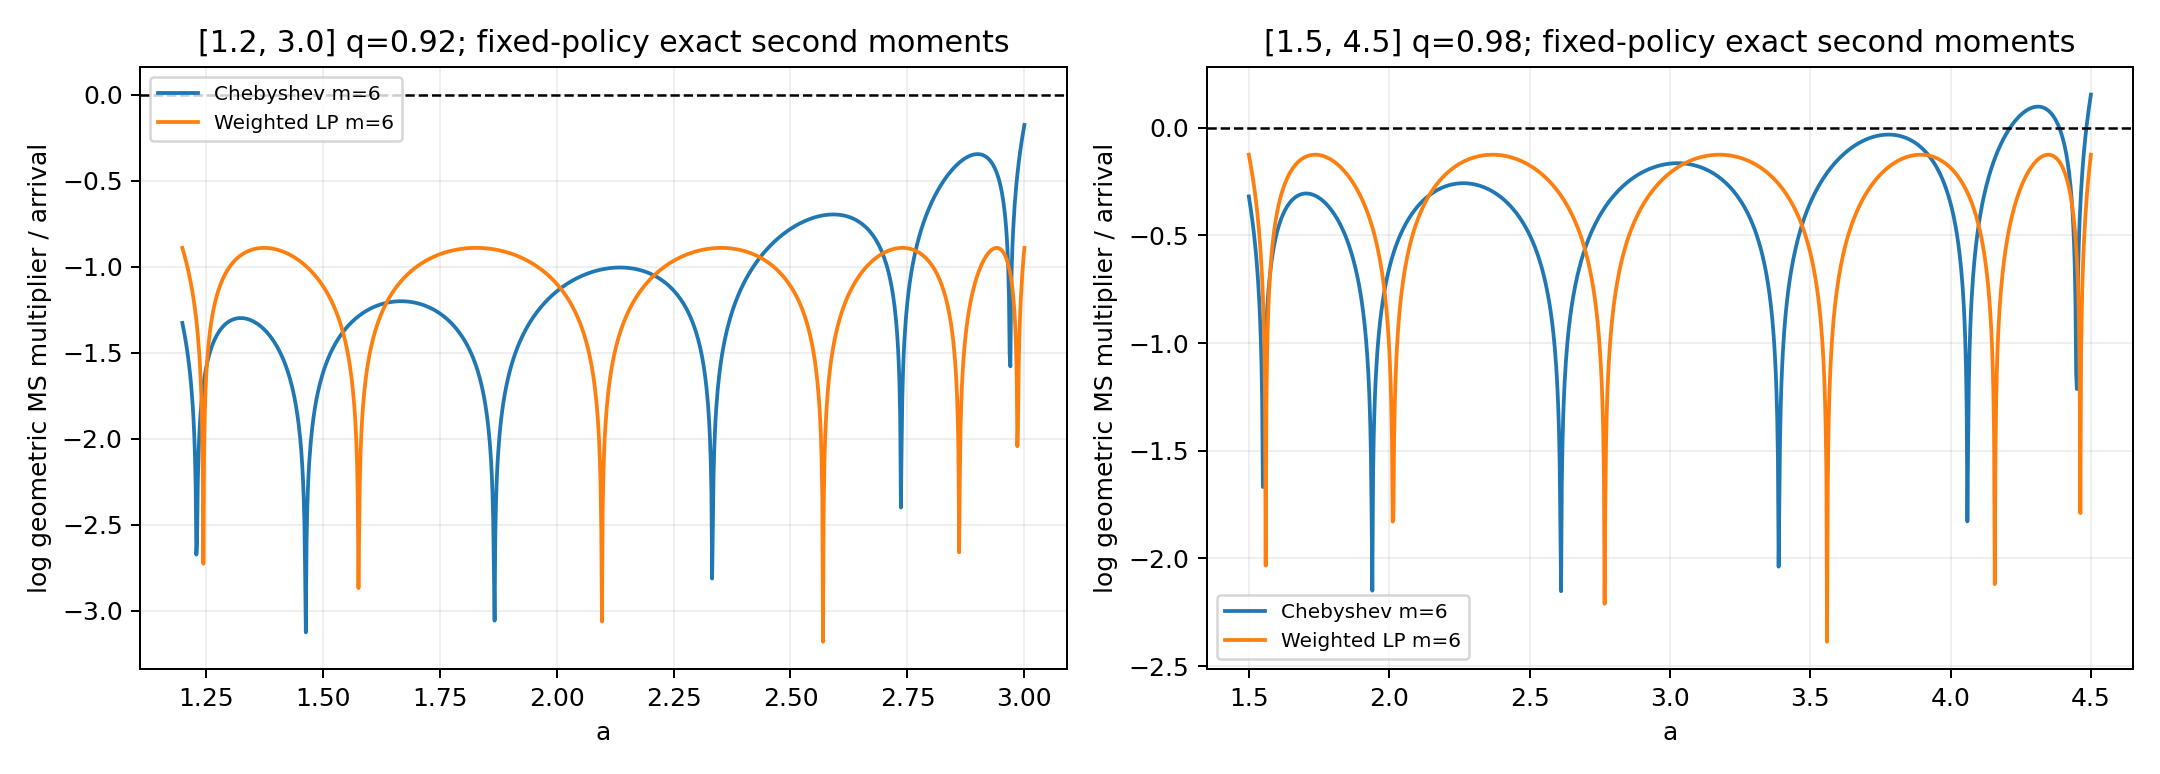

fig02_exact_asymptotic_costs.png


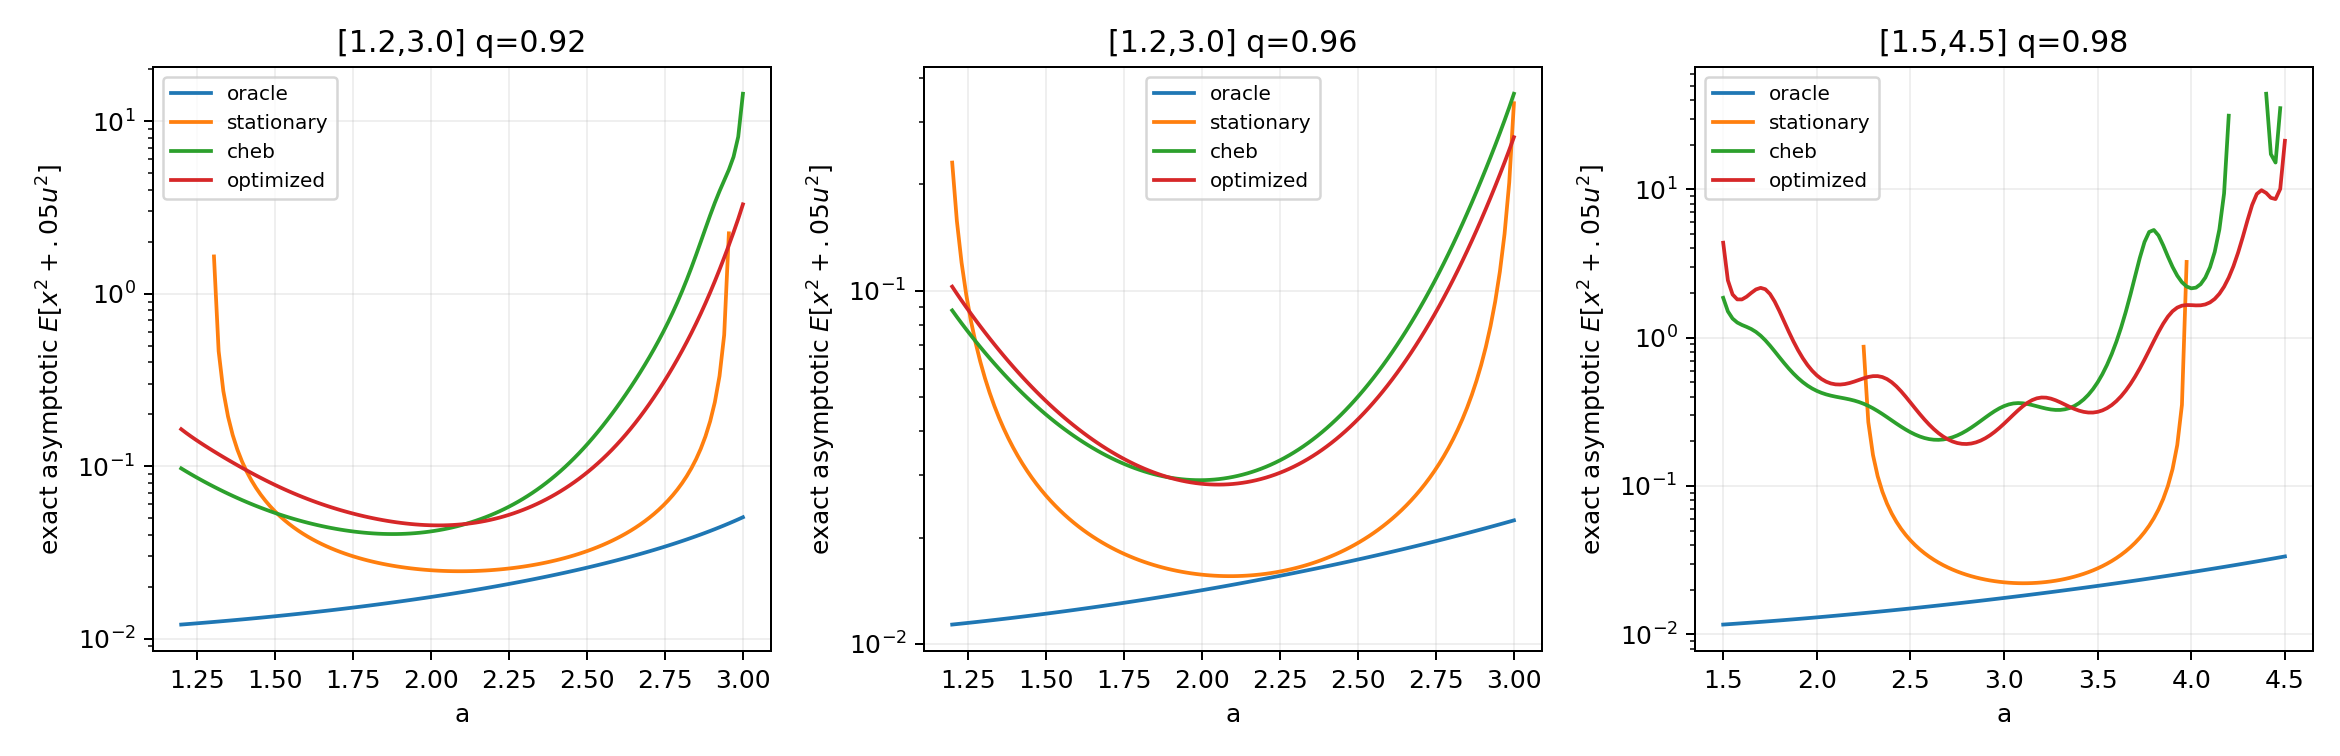

fig03_finite_horizon_mc.png


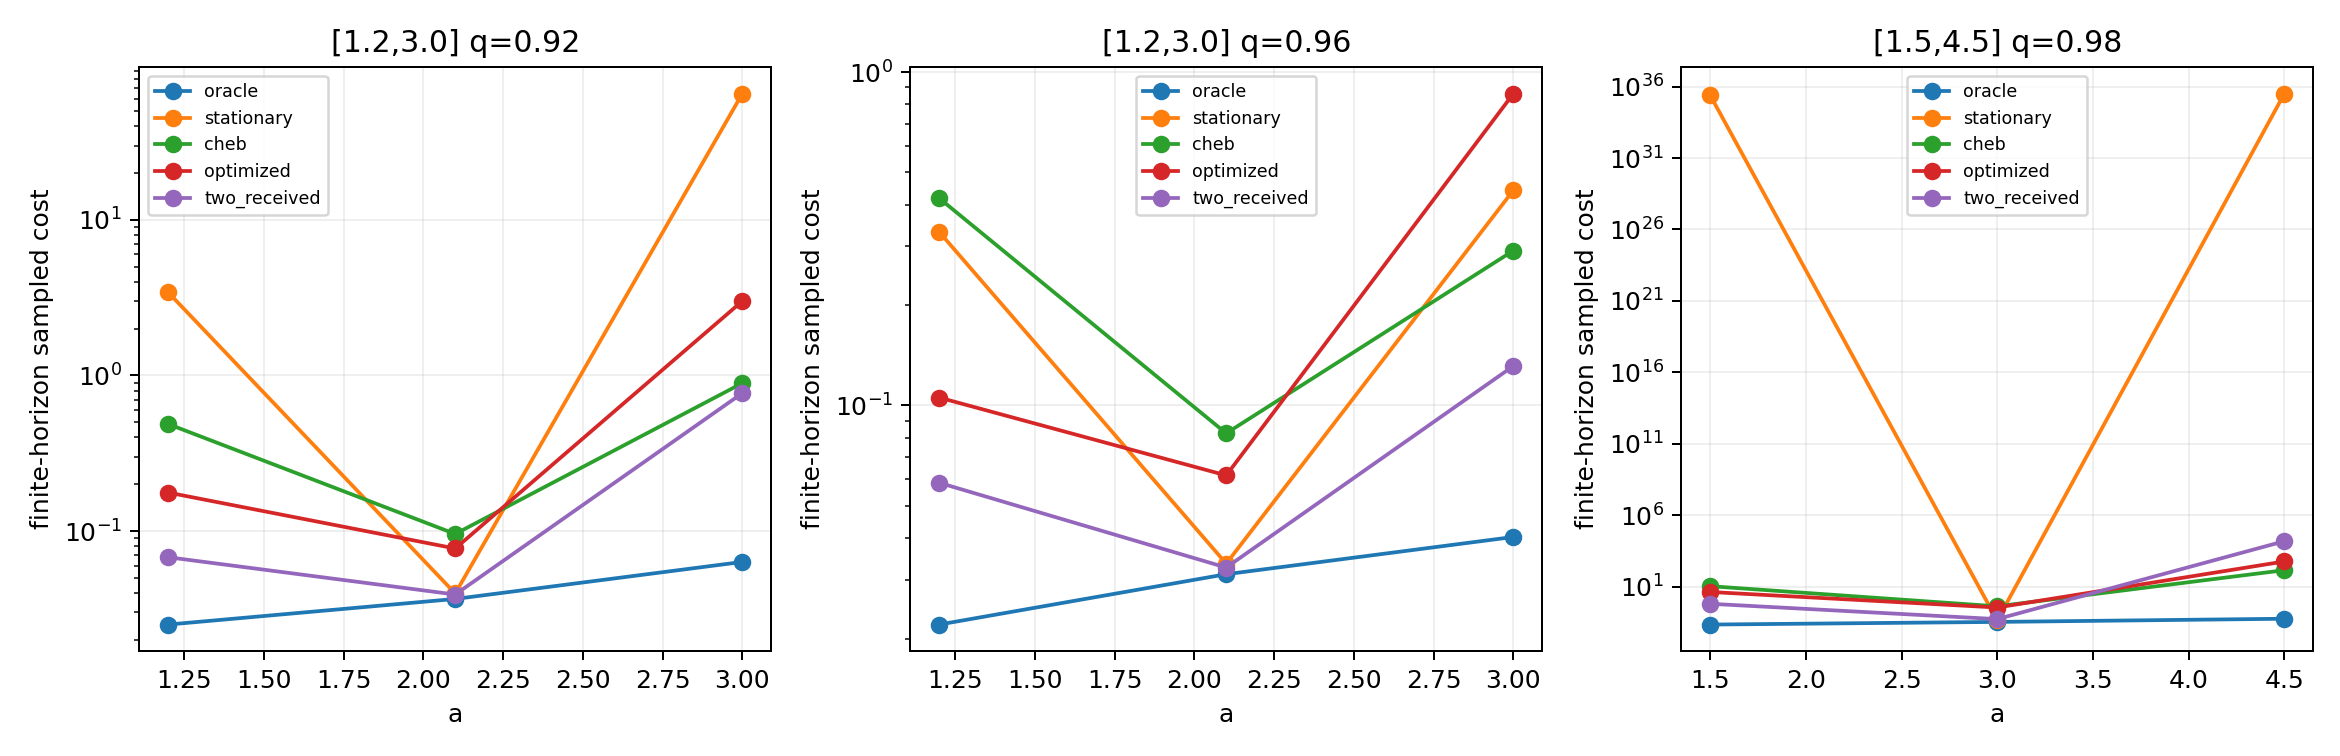

fig04_analytic_thresholds.png


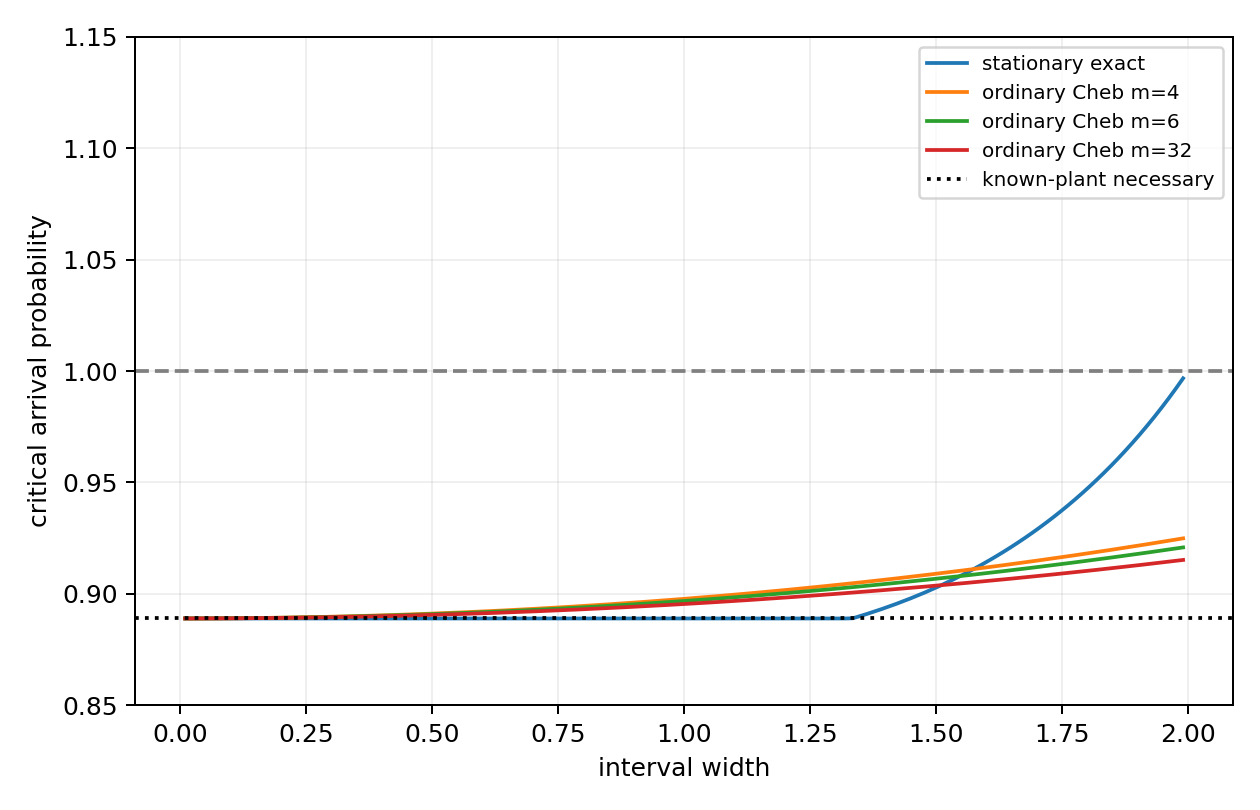

fig05_cost_aware_stationary.png


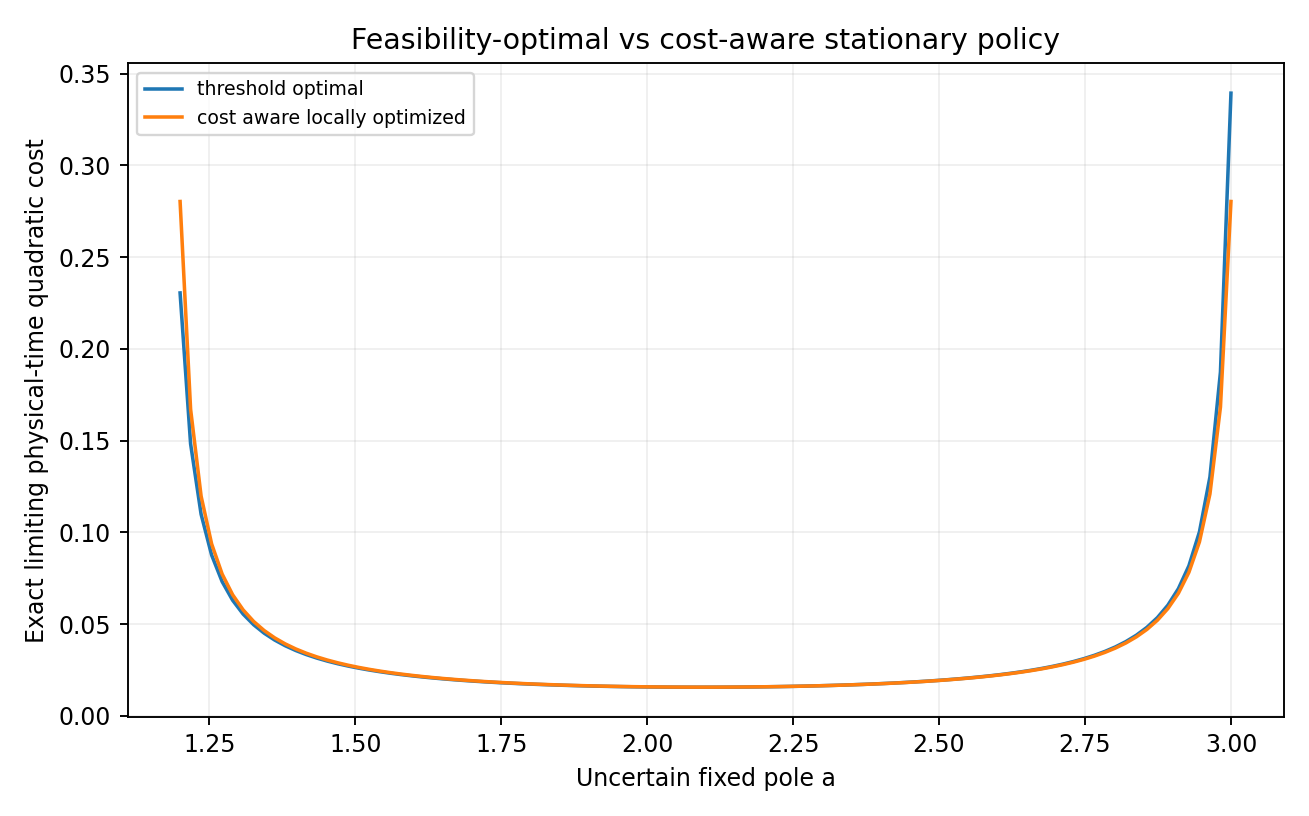

In [7]:
for fig in ['fig01_periodic_stability.png','fig02_exact_asymptotic_costs.png','fig03_finite_horizon_mc.png','fig04_analytic_thresholds.png','fig05_cost_aware_stationary.png']:
    print(fig);display(Image(filename=str(r/fig)))


In [8]:
# Downloadable machine-readable results created during this notebook run.
import shutil
out=shutil.make_archive(str(BASE/'IFAC_CPU_quick_generated_results'),'zip',root_dir=BASE,base_dir='results')
print('Generated archive:',out)
print('Warning: quick-profile Monte Carlo is illustrative; use standard ZIP for manuscript figures.')


Generated archive: /mnt/data/IFAC_2026_submission_consolidation/notebook/ifac_cpu_workspace/IFAC_CPU_quick_generated_results.zip


## Reproducibility and scientific integrity

The manuscript’s analytic results must be evaluated under the stated information classes. The saved period-six exact-rational checks certify idealized real-valued gain schedules over each full interval, not globally optimal periodic control or finite-precision hardware robustness. The memory-three, two-observation rational Lyapunov test addresses **two endpoints only**. The threshold and its Hardy-space proof are restricted to a fixed-but-unknown plant and a stationary age-indexed last-reception gain table. A conclusive bibliographic priority review and human proof review remain outstanding.